# 🏢 Building Component Segmentation for Thermal Images

**Simple & Reliable Methods for Segmenting: Walls, Windows, Roofs**

This notebook uses proven, lightweight methods that work well on thermal imagery.

## 1. Setup

In [1]:
# Install only what we need
!pip install -q scikit-image

import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from skimage import segmentation, color, filters, morphology
from skimage.segmentation import slic, mark_boundaries
from skimage.measure import regionprops, label
from scipy import ndimage
import warnings
warnings.filterwarnings('ignore')

print("✅ Setup complete!")

✅ Setup complete!


## 2. Upload Your Thermal Image

📤 Upload your thermal image:


Saving IRX_2927.JPG to IRX_2927.JPG

📐 Image shape: (512, 640, 3)


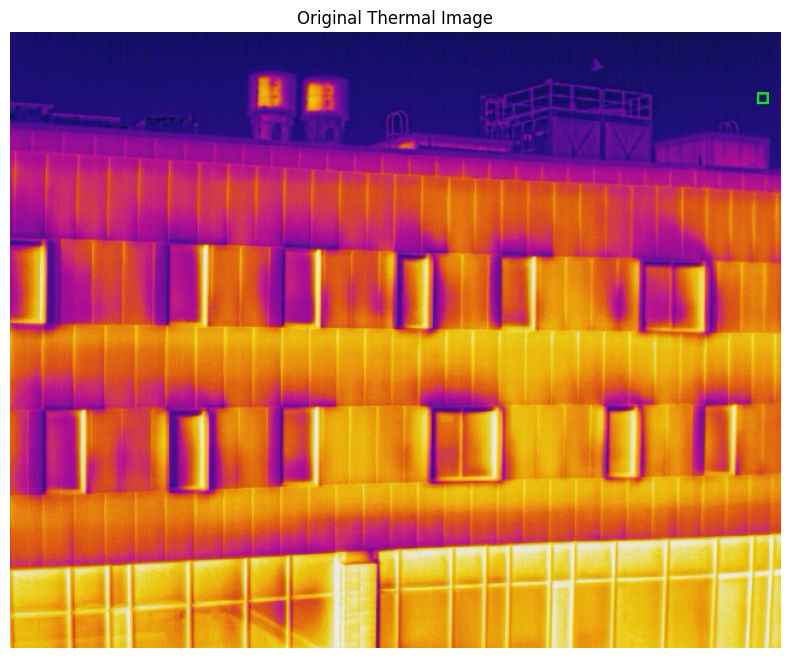

In [14]:
# Upload image
print("📤 Upload your thermal image:")
uploaded = files.upload()
IMAGE_PATH = list(uploaded.keys())[0]

# Load image
image = cv2.imread(IMAGE_PATH)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print(f"\n📐 Image shape: {image_rgb.shape}")

plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.title('Original Thermal Image')
plt.axis('off')
plt.show()

## 3. Preprocessing

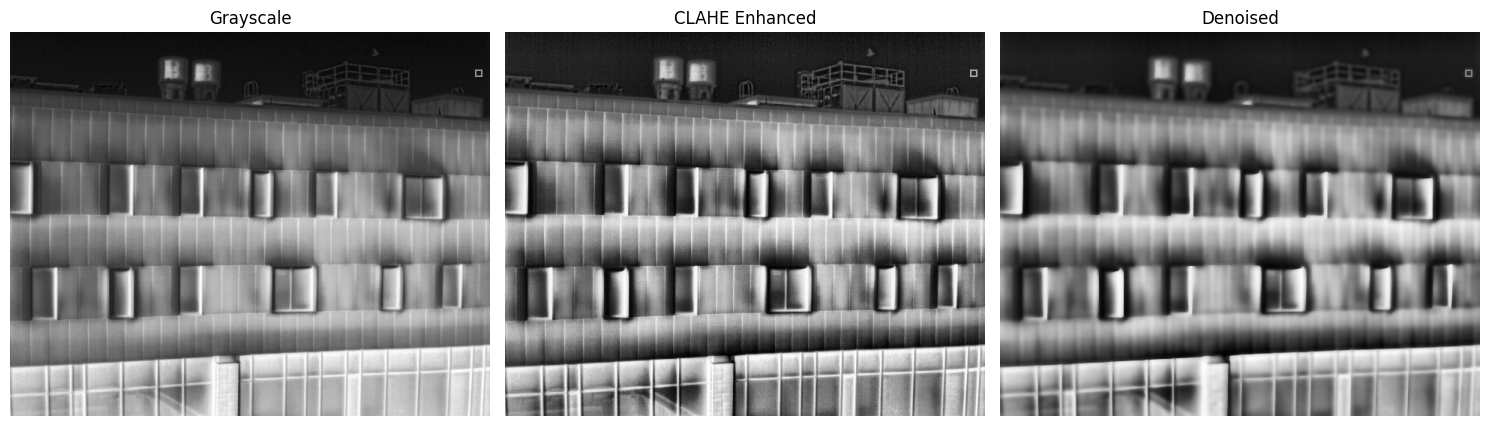

In [15]:
# Enhance contrast with CLAHE
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced = clahe.apply(gray)

# Denoise
denoised = cv2.bilateralFilter(enhanced, 9, 75, 75)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(gray, cmap='gray')
axes[0].set_title('Grayscale')
axes[1].imshow(enhanced, cmap='gray')
axes[1].set_title('CLAHE Enhanced')
axes[2].imshow(denoised, cmap='gray')
axes[2].set_title('Denoised')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Method 1: SLIC Superpixels
Groups similar pixels into meaningful regions

Created 49 superpixels


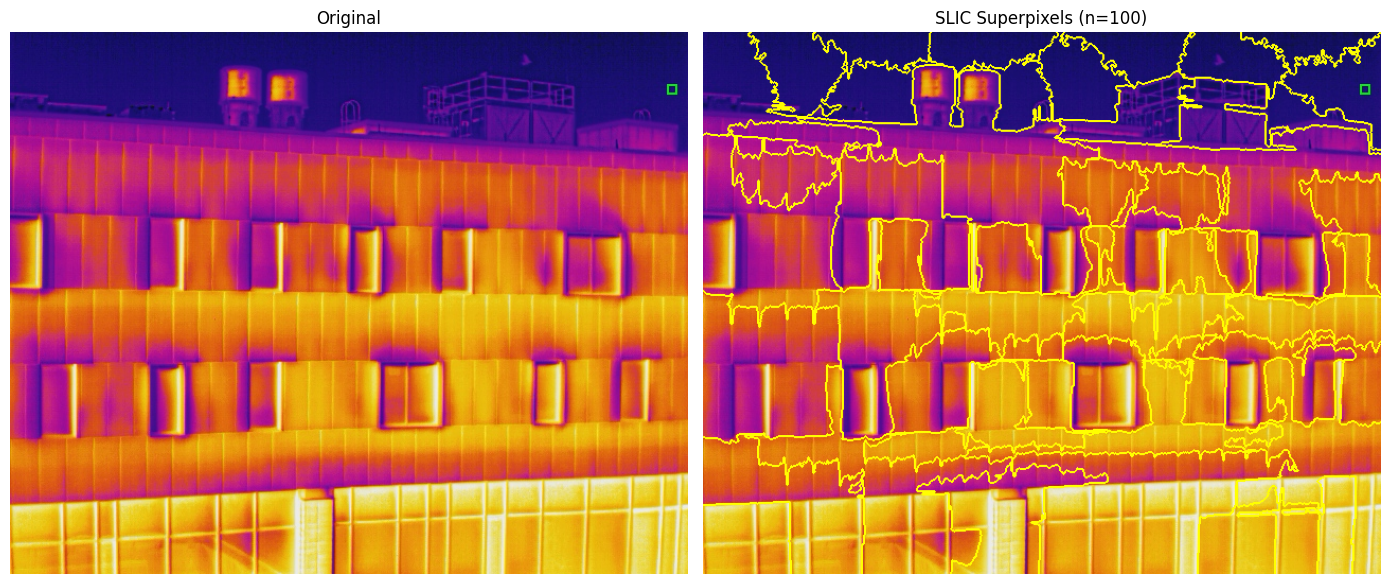

In [16]:
# SLIC superpixel segmentation
n_segments = 100  # Adjust: more = finer segmentation
segments_slic = slic(image_rgb, n_segments=n_segments, compactness=10, start_label=1)

print(f"Created {len(np.unique(segments_slic))} superpixels")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(image_rgb)
axes[0].set_title('Original')
axes[1].imshow(mark_boundaries(image_rgb, segments_slic))
axes[1].set_title(f'SLIC Superpixels (n={n_segments})')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Method 2: K-Means Clustering
Groups pixels by thermal intensity/color

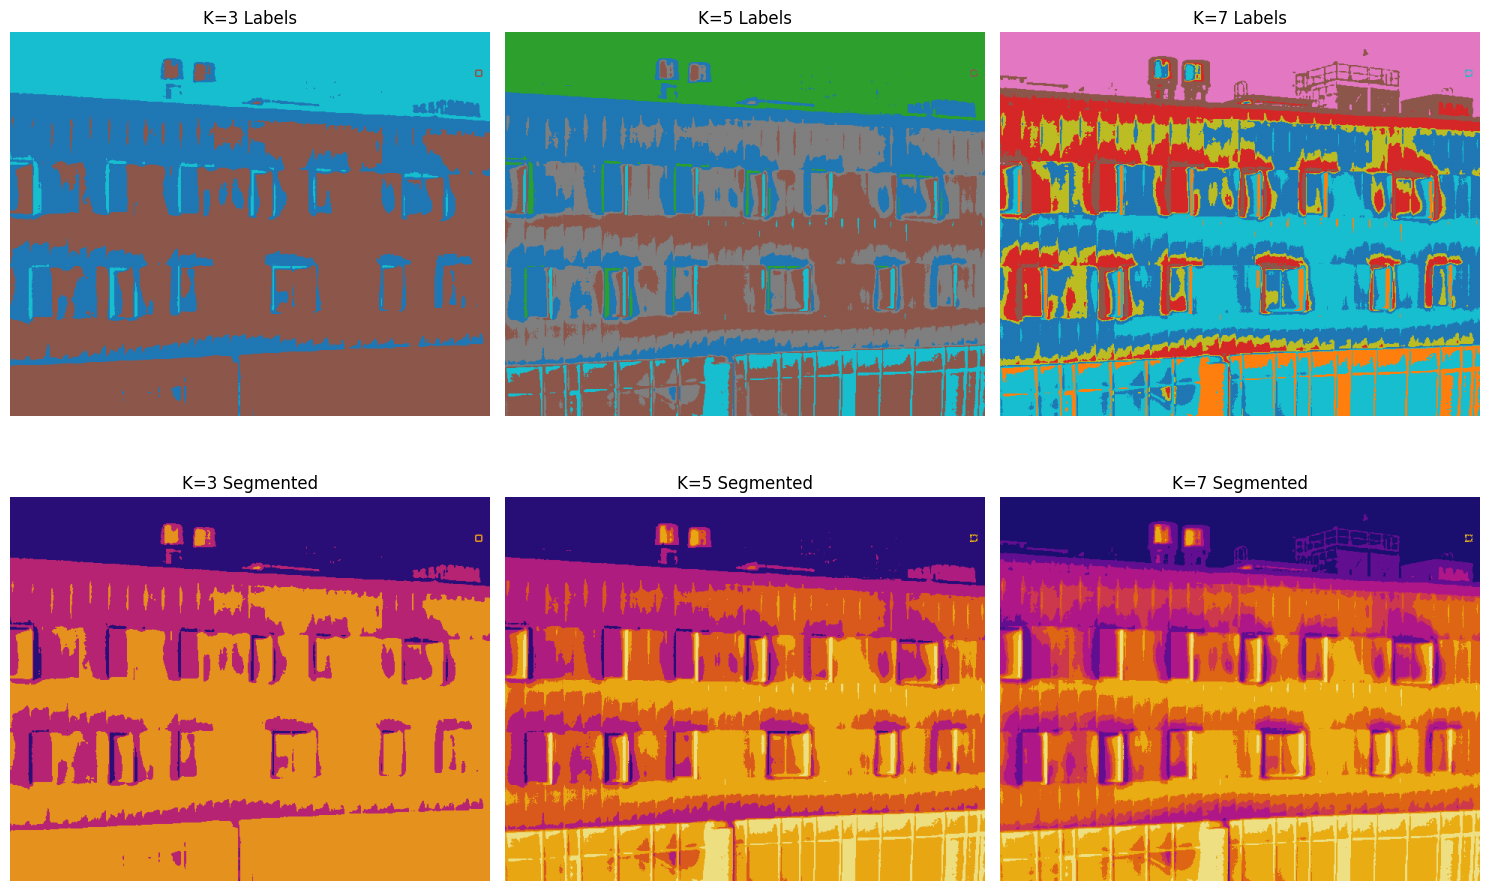

In [17]:
def kmeans_segmentation(image, k=5):
    """Segment image using K-means clustering"""
    # Reshape for k-means
    pixels = image.reshape(-1, 3).astype(np.float32)

    # K-means
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    _, labels, centers = cv2.kmeans(pixels, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    # Reshape back
    labels = labels.reshape(image.shape[:2])

    # Create colored result
    segmented = centers[labels.flatten()].reshape(image.shape).astype(np.uint8)

    return labels, segmented, centers

# Run k-means with different k values
k_values = [3, 5, 7]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, k in enumerate(k_values):
    labels, segmented, _ = kmeans_segmentation(image_rgb, k=k)

    axes[0, i].imshow(labels, cmap='tab10')
    axes[0, i].set_title(f'K={k} Labels')
    axes[0, i].axis('off')

    axes[1, i].imshow(segmented)
    axes[1, i].set_title(f'K={k} Segmented')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

# Store best result (k=5 usually works well)
kmeans_labels, kmeans_segmented, kmeans_centers = kmeans_segmentation(image_rgb, k=5)

## 6. Method 3: Edge-Based Segmentation
Detects boundaries between building components

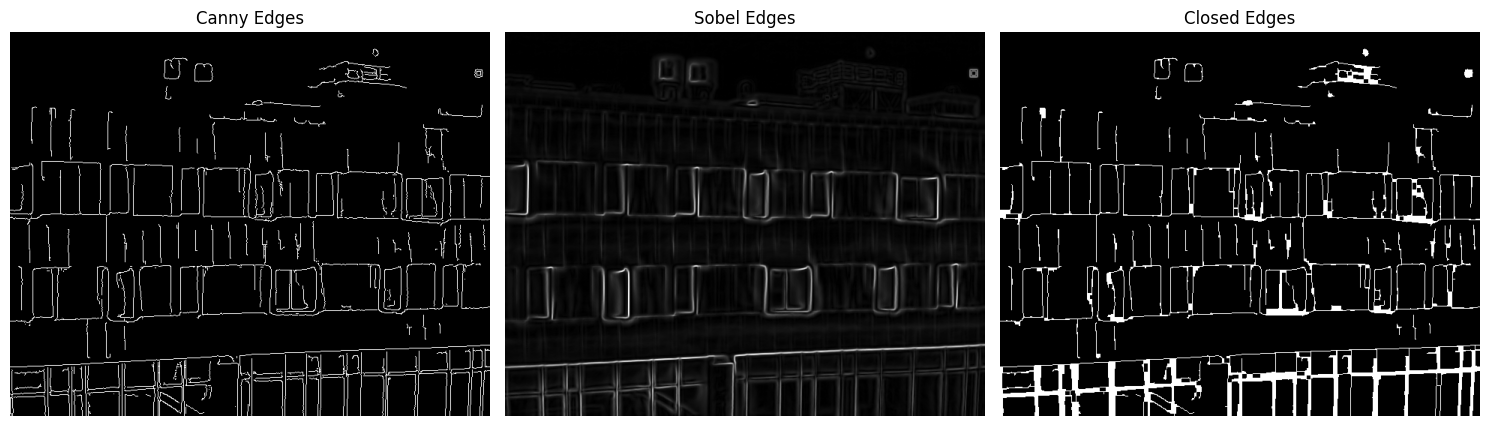

In [18]:
# Edge detection
edges_canny = cv2.Canny(denoised, 30, 100)
edges_sobel = filters.sobel(denoised)

# Close gaps in edges
kernel = np.ones((3, 3), np.uint8)
edges_closed = cv2.morphologyEx(edges_canny, cv2.MORPH_CLOSE, kernel, iterations=2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(edges_canny, cmap='gray')
axes[0].set_title('Canny Edges')
axes[1].imshow(edges_sobel, cmap='gray')
axes[1].set_title('Sobel Edges')
axes[2].imshow(edges_closed, cmap='gray')
axes[2].set_title('Closed Edges')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 7. Method 4: Watershed Segmentation
Treats image as topography and finds basins

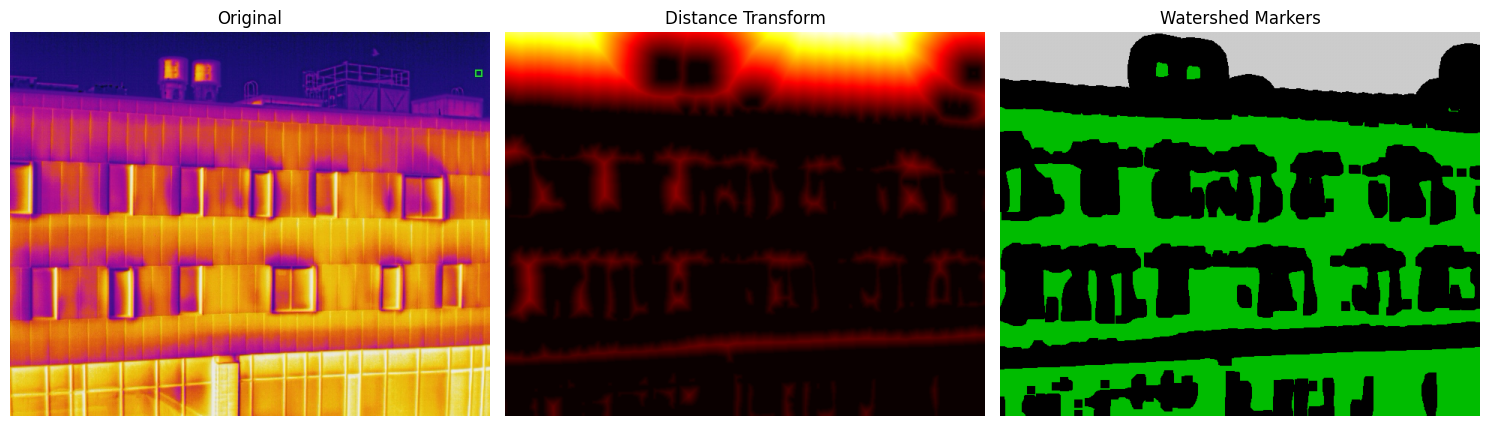

In [19]:
def watershed_segmentation(gray_img):
    """Watershed segmentation"""
    # Threshold
    _, thresh = cv2.threshold(gray_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Morphological operations
    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

    # Sure background
    sure_bg = cv2.dilate(opening, kernel, iterations=3)

    # Sure foreground
    dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
    _, sure_fg = cv2.threshold(dist_transform, 0.3 * dist_transform.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)

    # Unknown region
    unknown = cv2.subtract(sure_bg, sure_fg)

    # Markers
    _, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0

    return markers, dist_transform

watershed_markers, dist_transform = watershed_segmentation(denoised)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image_rgb)
axes[0].set_title('Original')
axes[1].imshow(dist_transform, cmap='hot')
axes[1].set_title('Distance Transform')
axes[2].imshow(watershed_markers, cmap='nipy_spectral')
axes[2].set_title('Watershed Markers')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 8. Window Detection
Windows appear as cooler (darker) rectangular regions in thermal images

🪟 Detected 11 potential windows


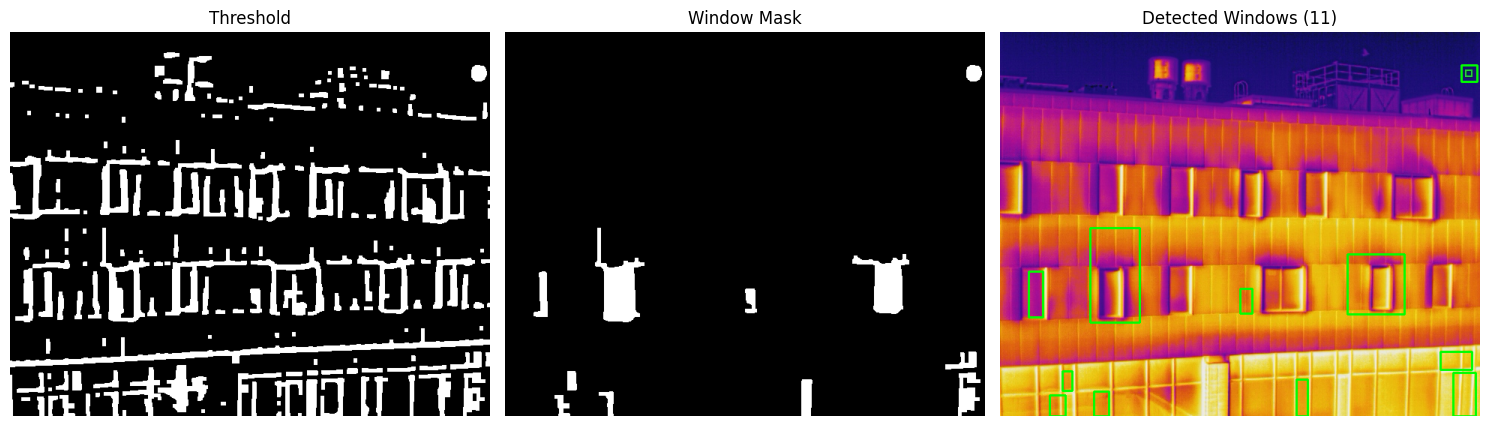

In [20]:
def detect_windows(gray_img, min_area=200, max_area=15000):
    """Detect rectangular window-like regions"""
    # Adaptive threshold to find darker regions
    thresh = cv2.adaptiveThreshold(gray_img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, 21, 5)

    # Clean up
    kernel = np.ones((5, 5), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

    # Find contours
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    windows = []
    window_mask = np.zeros_like(gray_img)

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if min_area < area < max_area:
            x, y, w, h = cv2.boundingRect(cnt)
            aspect = w / max(h, 1)

            # Windows are roughly rectangular
            if 0.3 < aspect < 3.0:
                rect_area = w * h
                extent = area / rect_area if rect_area > 0 else 0

                if extent > 0.4:  # Reasonably rectangular
                    windows.append({
                        'contour': cnt,
                        'bbox': (x, y, w, h),
                        'area': area
                    })
                    cv2.drawContours(window_mask, [cnt], -1, 255, -1)

    return windows, window_mask, thresh

windows, window_mask, window_thresh = detect_windows(denoised)
print(f"🪟 Detected {len(windows)} potential windows")

# Visualize
result = image_rgb.copy()
for w in windows:
    x, y, width, h = w['bbox']
    cv2.rectangle(result, (x, y), (x+width, y+h), (0, 255, 0), 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(window_thresh, cmap='gray')
axes[0].set_title('Threshold')
axes[1].imshow(window_mask, cmap='gray')
axes[1].set_title('Window Mask')
axes[2].imshow(result)
axes[2].set_title(f'Detected Windows ({len(windows)})')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 9. Classify Building Components
Combine methods to identify roof, walls, and windows

In [21]:
def classify_components(image_rgb, kmeans_labels, window_mask):
    """
    Classify image regions into building components based on:
    - Position (top = roof, middle/bottom = walls)
    - Thermal intensity
    - Already detected windows
    """
    h, w = image_rgb.shape[:2]
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    # Initialize masks
    roof_mask = np.zeros((h, w), dtype=np.uint8)
    wall_mask = np.zeros((h, w), dtype=np.uint8)

    # Analyze each k-means cluster
    for cluster_id in np.unique(kmeans_labels):
        cluster_mask = (kmeans_labels == cluster_id).astype(np.uint8)

        # Get cluster properties
        coords = np.where(cluster_mask)
        if len(coords[0]) == 0:
            continue

        center_y = np.mean(coords[0])
        mean_intensity = np.mean(gray[cluster_mask > 0])
        area = np.sum(cluster_mask)

        # Skip small regions
        if area < 500:
            continue

        # Classification logic
        relative_y = center_y / h

        # Roof: upper 40% of image
        if relative_y < 0.4:
            roof_mask = np.maximum(roof_mask, cluster_mask * 255)
        # Walls: everything else (excluding windows)
        else:
            wall_mask = np.maximum(wall_mask, cluster_mask * 255)

    # Remove window areas from wall mask
    wall_mask[window_mask > 0] = 0

    return {
        'roof': roof_mask,
        'wall': wall_mask,
        'window': window_mask
    }

component_masks = classify_components(image_rgb, kmeans_labels, window_mask)

# Print stats
print("📊 Component Statistics:")
for name, mask in component_masks.items():
    pixels = np.sum(mask > 0)
    pct = pixels / mask.size * 100
    print(f"  {name}: {pixels:,} pixels ({pct:.1f}%)")

📊 Component Statistics:
  roof: 62,530 pixels (19.1%)
  wall: 254,896 pixels (77.8%)
  window: 11,173 pixels (3.4%)


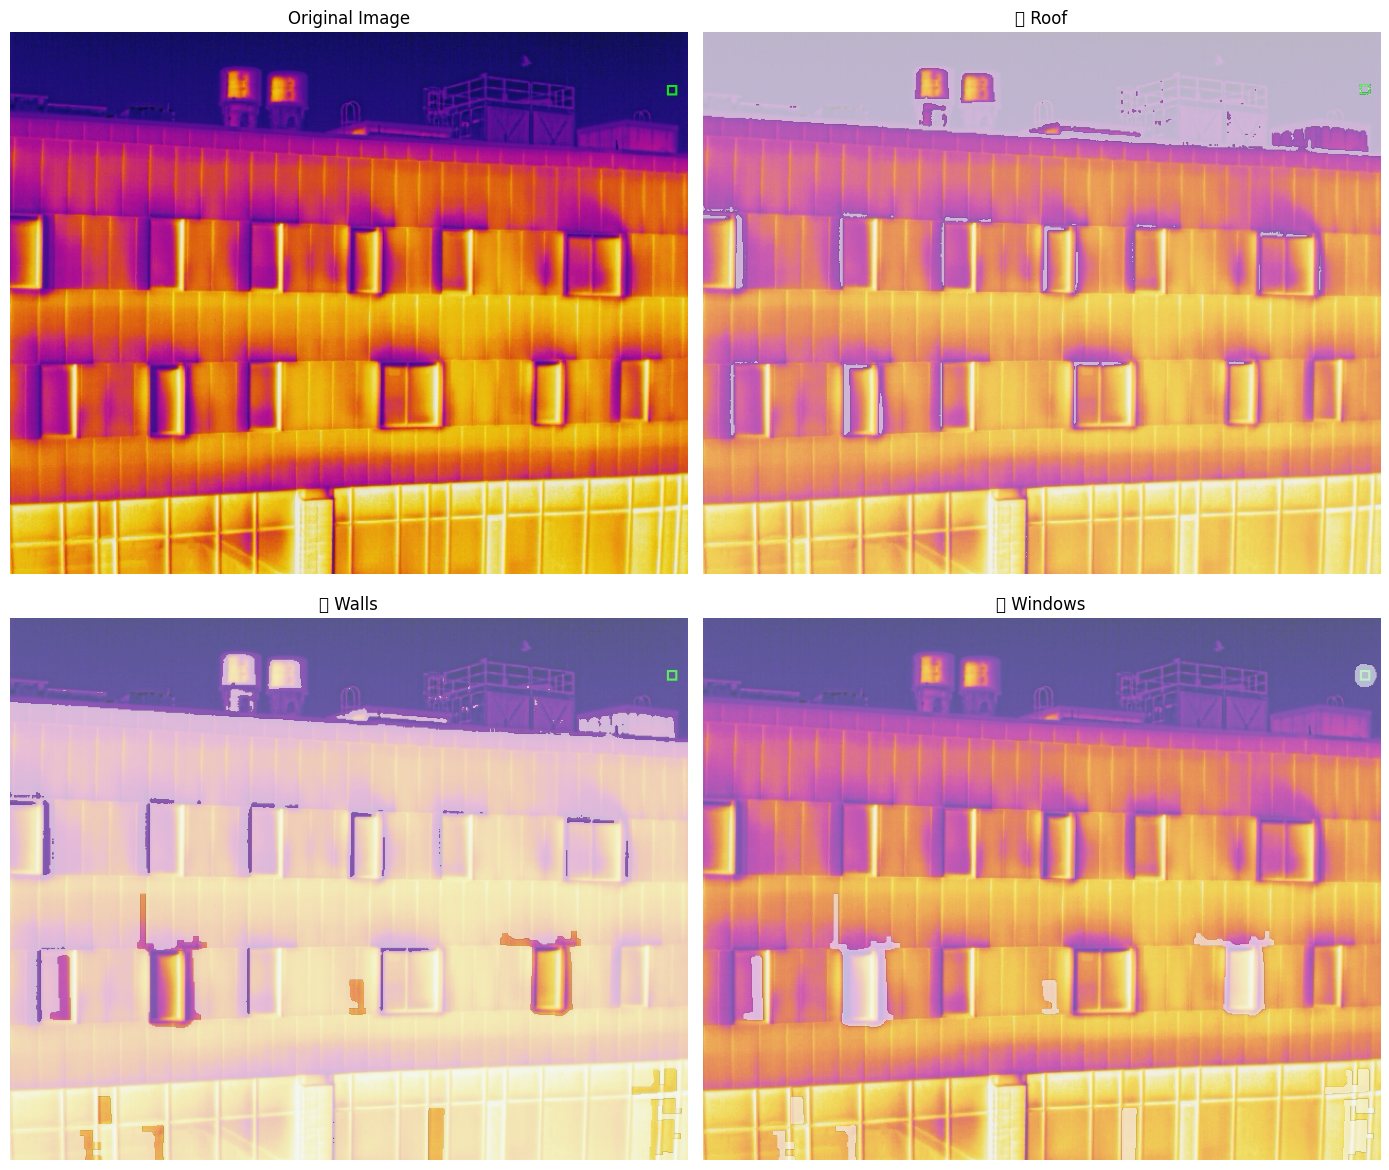

In [22]:
# Visualize classified components
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Original
axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

# Individual components
colors = {'roof': 'Reds', 'wall': 'Greens', 'window': 'Blues'}
titles = {'roof': '🏠 Roof', 'wall': '🧱 Walls', 'window': '🪟 Windows'}

for i, (name, cmap) in enumerate(colors.items()):
    ax = axes.flatten()[i + 1]
    ax.imshow(image_rgb, alpha=0.7)
    mask = component_masks[name]
    masked = np.ma.masked_where(mask == 0, mask)
    ax.imshow(masked, cmap=cmap, alpha=0.6)
    ax.set_title(titles[name])
    ax.axis('off')

plt.tight_layout()
plt.show()

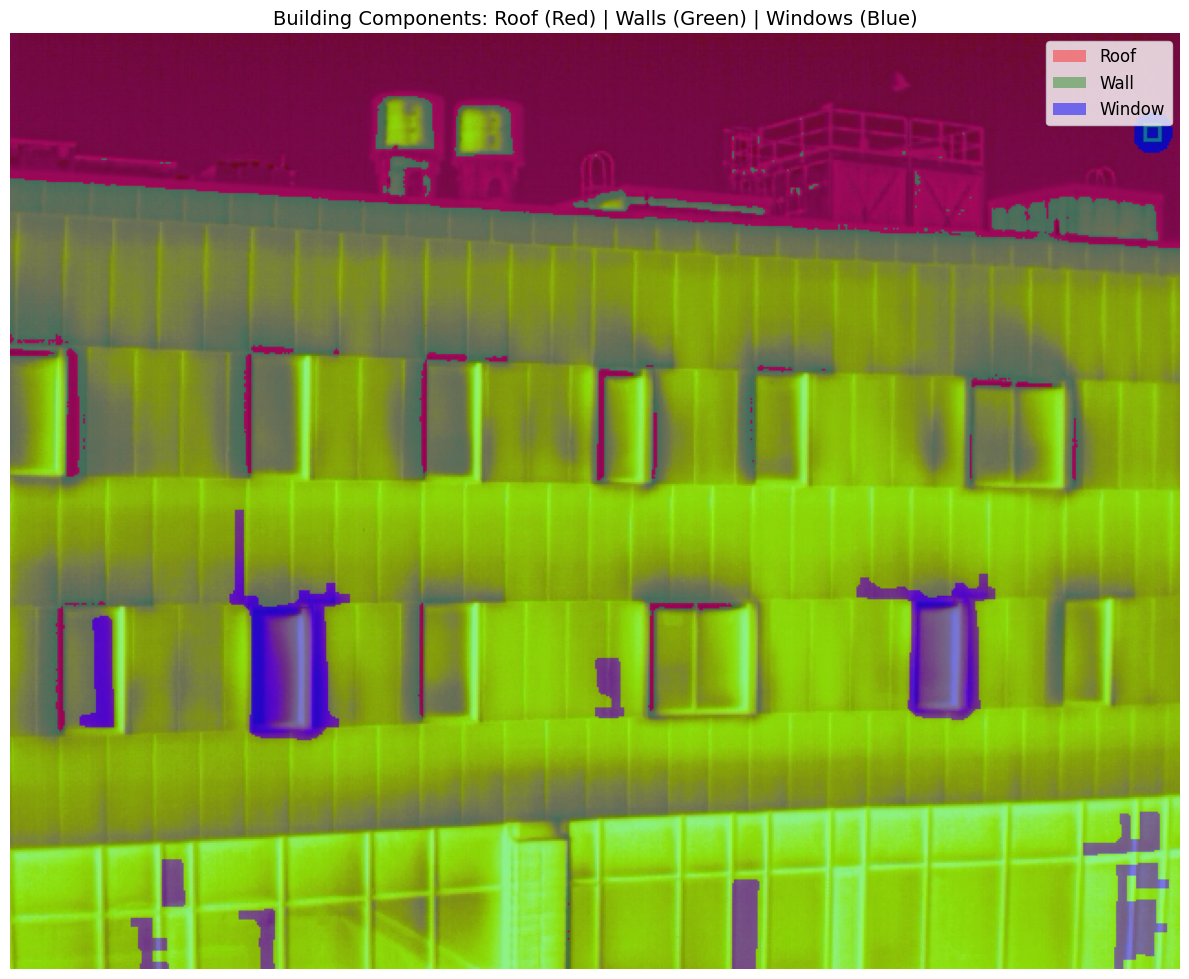

In [23]:
# Combined visualization
fig, ax = plt.subplots(figsize=(12, 10))

ax.imshow(image_rgb)

# Overlay each component with different color
overlay = np.zeros((*image_rgb.shape[:2], 4))

# Roof - Red
overlay[component_masks['roof'] > 0] = [1, 0, 0, 0.4]
# Wall - Green
overlay[component_masks['wall'] > 0] = [0, 1, 0, 0.4]
# Window - Blue
overlay[component_masks['window'] > 0] = [0, 0, 1, 0.5]

ax.imshow(overlay)
ax.set_title('Building Components: Roof (Red) | Walls (Green) | Windows (Blue)', fontsize=14)
ax.axis('off')

# Legend
from matplotlib.patches import Patch
legend = [
    Patch(facecolor='red', alpha=0.4, label='Roof'),
    Patch(facecolor='green', alpha=0.4, label='Wall'),
    Patch(facecolor='blue', alpha=0.5, label='Window')
]
ax.legend(handles=legend, loc='upper right', fontsize=12)

plt.tight_layout()
plt.show()

## 10. Thermal Analysis per Component
Extract temperature statistics for anomaly detection

In [12]:
def analyze_thermal_stats(gray_img, component_masks):
    """Calculate thermal statistics for each component"""
    stats = {}

    for name, mask in component_masks.items():
        if np.sum(mask > 0) > 0:
            values = gray_img[mask > 0]
            stats[name] = {
                'mean': np.mean(values),
                'std': np.std(values),
                'min': np.min(values),
                'max': np.max(values),
                'median': np.median(values),
                'pixels': len(values)
            }

    return stats

thermal_stats = analyze_thermal_stats(gray, component_masks)

print("\n" + "="*60)
print("🌡️  THERMAL STATISTICS BY COMPONENT")
print("="*60)

for component, stats in thermal_stats.items():
    print(f"\n{component.upper()}:")
    print(f"  Mean Intensity:   {stats['mean']:.1f}")
    print(f"  Std Deviation:    {stats['std']:.1f}")
    print(f"  Range:            {stats['min']} - {stats['max']}")
    print(f"  Median:           {stats['median']:.1f}")
    print(f"  Pixels:           {stats['pixels']:,}")


🌡️  THERMAL STATISTICS BY COMPONENT

WALL:
  Mean Intensity:   153.5
  Std Deviation:    50.3
  Range:            13 - 238
  Median:           150.0
  Pixels:           314,463

WINDOW:
  Mean Intensity:   92.6
  Std Deviation:    35.3
  Range:            22 - 216
  Median:           90.0
  Pixels:           13,217


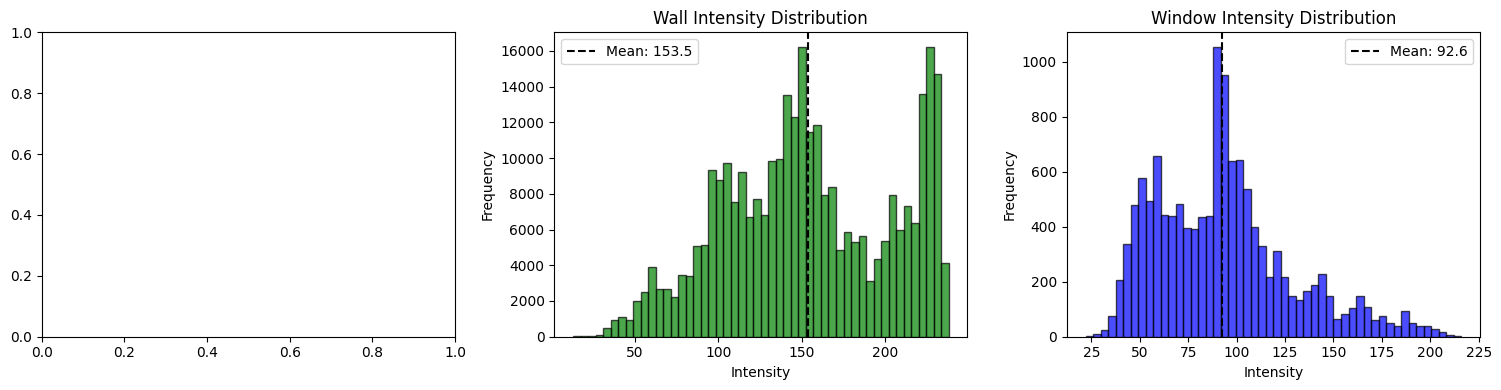

In [13]:
# Histogram comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

colors_hist = {'roof': 'red', 'wall': 'green', 'window': 'blue'}

for i, (name, color) in enumerate(colors_hist.items()):
    mask = component_masks[name]
    if np.sum(mask > 0) > 0:
        values = gray[mask > 0]
        axes[i].hist(values, bins=50, color=color, alpha=0.7, edgecolor='black')
        axes[i].axvline(np.mean(values), color='black', linestyle='--', label=f'Mean: {np.mean(values):.1f}')
        axes[i].set_title(f'{name.capitalize()} Intensity Distribution')
        axes[i].set_xlabel('Intensity')
        axes[i].set_ylabel('Frequency')
        axes[i].legend()

plt.tight_layout()
plt.show()

## 11. Export Results

In [ ]:
import os

# Create output directory
output_dir = 'segmentation_results'
os.makedirs(output_dir, exist_ok=True)

# Save masks
for name, mask in component_masks.items():
    cv2.imwrite(f'{output_dir}/{name}_mask.png', mask)

    # Save masked region
    masked_region = image_rgb.copy()
    masked_region[mask == 0] = 0
    cv2.imwrite(f'{output_dir}/{name}_region.png', cv2.cvtColor(masked_region, cv2.COLOR_RGB2BGR))

# Save combined labels
combined = np.zeros(gray.shape, dtype=np.uint8)
combined[component_masks['roof'] > 0] = 1
combined[component_masks['wall'] > 0] = 2
combined[component_masks['window'] > 0] = 3
cv2.imwrite(f'{output_dir}/combined_labels.png', combined)

# Save numpy data
np.savez(f'{output_dir}/segmentation_data.npz',
         image=image_rgb,
         gray=gray,
         combined_labels=combined,
         roof_mask=component_masks['roof'],
         wall_mask=component_masks['wall'],
         window_mask=component_masks['window'],
         thermal_stats=thermal_stats)

print(f"✅ Results saved to '{output_dir}/' directory")
print(f"\nFiles created:")
for f in os.listdir(output_dir):
    print(f"  - {f}")

In [ ]:
# Download results
!zip -r segmentation_results.zip segmentation_results/
files.download('segmentation_results.zip')
print("\n📥 Download started!")

## 12. Load Results for Anomaly Detection (Next Step)

Use this code to load the segmentation data:

In [ ]:
# Example: Load saved data
data = np.load('segmentation_results/segmentation_data.npz', allow_pickle=True)

print("Available arrays:")
for key in data.files:
    print(f"  - {key}: {data[key].shape if hasattr(data[key], 'shape') else type(data[key])}")

# Access individual masks
roof = data['roof_mask']
wall = data['wall_mask']
window = data['window_mask']

print("\n✅ Data loaded and ready for anomaly detection!")

---
## Summary

This notebook segments thermal building images using:

1. **SLIC Superpixels** - Groups similar pixels
2. **K-Means Clustering** - Segments by thermal intensity
3. **Edge Detection** - Finds boundaries
4. **Watershed** - Identifies distinct regions
5. **Window Detection** - Finds rectangular cooler areas

**Output for Anomaly Detection:**
- Individual masks for roof, walls, windows
- Thermal statistics per component
- Ready-to-load `.npz` file

**Next Step:** Use the component masks to detect thermal anomalies (hot spots, cold bridges, insulation defects) within each building component.